### Part 1 - Probability

- Probability ~ measure of the likelihood that an event will occur
    - Expressed as a number between 0 and 1, where 0 indicates impossibility and 1 indicates certainty.
    - The sum of probabilities for all possible outcomes in a given scenario is always equal to 1.



<img src="https://i.ibb.co/SpzXn0F/probability.png" width="600">

- **Probability distribution** is a function describing the likelihood of different outcomes in a random experiment. Two main types:
    - Discrete probability distributions deal with random variables that can only take on specific, countable values.
    - Continuous probability distributions, like the **Normal Distribution**, that can take on any value within a specified range.

### Part 2 - Normal Distribution

<img src="https://i.ibb.co/tPTnHkr5/normal-distribution.png" width="800">

- **Normal Distribution**, known as the **Gaussian Distribution** is a **continuous probability distribution** with the following attributes


> 1. **Bell-shaped curve**: The Normal Distribution is represented by a symmetric, bell-shaped curve known as the "Gaussian curve" or "bell curve."
>>   - The peak of the curve represents the mean (μ) of the distribution, and the curve is symmetric about this mean.

> 2. **Mean, median, and mode**: In a Normal Distribution, the mean, median, and mode are all equal. This is a result of the distribution's symmetry.

> 3. **Symmetry**: The Normal Distribution is symmetric about its mean. This means that the left and right halves of the distribution are mirror images of each other.

> 4. **Asymptotes**: (/ˈæs.əmˌtoʊt/) The tails of the Normal Distribution curve approach the x-axis but never touch it. These tails extend infinitely in both directions, meaning that the range of the Normal Distribution is from negative infinity to positive infinity.

> 5. **Area under the curve**: The total area under the Normal Distribution curve is equal to 1. This property allows us to calculate probabilities by finding the area under the curve between specific points.

> 6. **Parametric distribution**: The Normal Distribution is a parametric distribution, which means it is fully described by its parameters: the mean (μ) and the standard deviation (σ). The mean determines the location of the center of the distribution, while the standard deviation determines the width and height of the curve.

>>   - The mathematical formula for the Normal Distribution is:

  >>>   $f(x) = \frac{1}{\sigma\sqrt{2\pi}}e^{-\frac{1}{2}(\frac{x-\mu}{\sigma})^2}$

  >>> where:
  >>> - $f(x)$ is the probability density function (PDF)
     - $\mu$ is the mean
     - $\sigma$ is the standard deviation
     - $\pi$ is the mathematical constant pi (approximately 3.14159)
     - $e$ is the mathematical constant e (approximately 2.71828)

> 7. **Empirical rule**: The Empirical Rule, also known as the 68-95-99.7 Rule, states that for a Normal Distribution:
   - Approximately 68% of the data falls within one standard deviation of the mean (μ ± σ).
   - Approximately 95% of the data falls within two standard deviations of the mean (μ ± 2σ).
   - Approximately 99.7% of the data falls within three standard deviations of the mean (μ ± 3σ).

These properties make the Normal Distribution a valuable tool for modeling and analyzing real-world phenomena, as many natural processes and measurements tend to follow a Normal Distribution.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Define our height distribution parameters
mu = 170  # mean height in cm
sigma = 7  # standard deviation in cm

# Create height distribution
height_dist = stats.norm(mu, sigma)

sample_heights = np.random.normal(mu, sigma, 1_000) # some samples
sample_heights[:10]

array([173.35233214, 172.10431036, 167.70771736, 152.88965169,
       179.74181082, 163.34901383, 170.15804574, 161.75462658,
       178.97856731, 165.95972811])

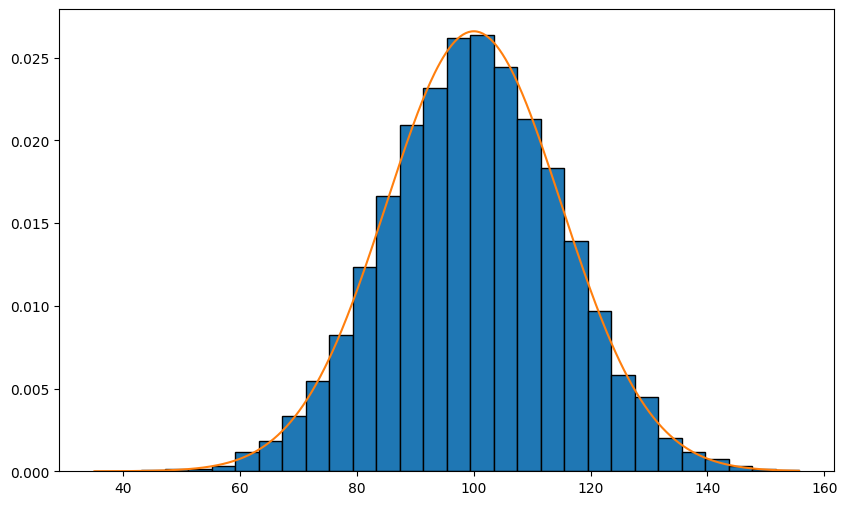

In [7]:
mean = 100
std = 15

plt.figure(figsize=(10,6))
iq_sample = np.random.normal(mean,std,10000)
plt.hist(iq_sample,bins=30,density=True,edgecolor='black')

x_values = np.linspace(min(iq_sample), max(iq_sample), 500)
pdf_values = stats.norm(mean,std).pdf(x_values)

plt.plot(x_values,pdf_values)

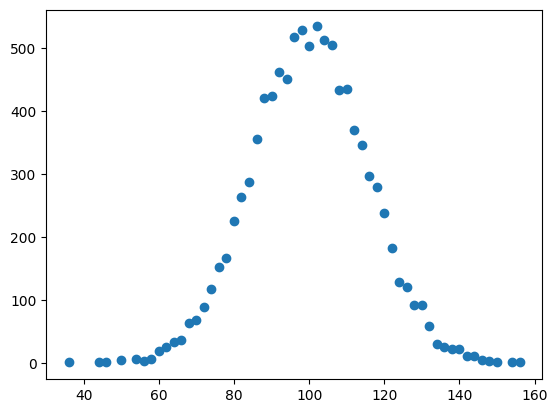

In [21]:
from collections import Counter

iq_counter = Counter([(iq/2).round()*2 for iq in iq_sample])
plt.scatter(list(iq_counter.keys()),list(iq_counter.values()))

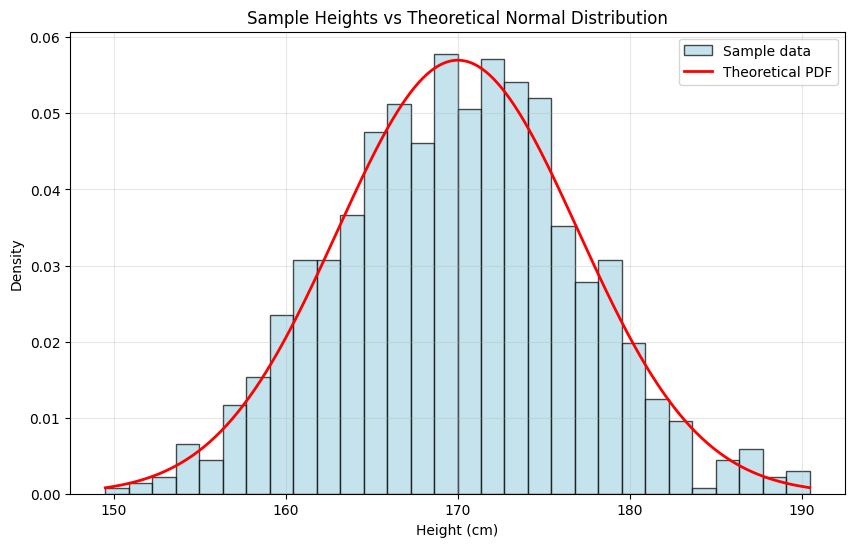

In [3]:
# Plot histogram with theoretical curve
plt.figure(figsize=(10, 6))
plt.hist(sample_heights,
         bins=30,
         density=True,
         alpha=0.7,
         color='lightblue',
         edgecolor='black',
         label='Sample data')

# Create x-values and compute PDF
x_values = np.linspace(min(sample_heights), max(sample_heights), 500)
pdf_values = height_dist.pdf(x_values)

# Plot theoretical curve
plt.plot(x_values, pdf_values, 'r-', linewidth=2, label='Theoretical PDF')

plt.xlabel('Height (cm)')
plt.ylabel('Density')
plt.title('Sample Heights vs Theoretical Normal Distribution')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Part 3 - Standard Normal Distribution

The Standard Normal Distribution, also known as the Z-distribution
- mean of 0 and a standard deviation of 1. It is denoted as:

$Z \sim N(0, 1)$

Allows to compare and standardize data from different Normal Distributions.

<img src="https://i.ibb.co/rGXgJRyL/standard-normal-dist.png" width="800">

To convert a random variable X from a Normal Distribution with mean μ and standard deviation σ to a Standard Normal Distribution, we use the following formula:

$Z = \frac{X - \mu}{\sigma}$

This process is called standardization or Z-score normalization. The resulting Z-score represents the number of standard deviations an observation is away from the mean.


For example, suppose we have a Normal Distribution with a mean of 170 and a standard deviation of 7. If we observe a value of 177, we can calculate its Z-score as follows:

$Z = \frac{177 - 170}{7} = 1$

This means that the observation of 177 is one standard deviation above the mean.


In [ ]:
# Create x-values for original height distribution
x = np.linspace(mu - 4*sigma, mu + 4*sigma, 1000)
pdf_values = stats.norm(mu, sigma).pdf(x)

# Visualize standardization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Original height distribution
ax1.plot(x, pdf_values, 'b-', linewidth=2)


heights_to_check = [165, 170, 175, 180, 185]
for height in heights_to_check:
    ax1.axvline(height, color='red', linestyle='--', alpha=0.7)
ax1.set_xlabel('Height (cm)')
ax1.set_ylabel('Density')
ax1.set_title('Original Height Distribution')
ax1.grid(True, alpha=0.3)



# Standardized distribution
z = np.linspace(-4, 4, 1000)
standard_pdf = stats.norm(0, 1).pdf(z)
ax2.plot(z, standard_pdf, 'g-', linewidth=2)


z_scores = [(height - mu) / sigma for height in heights_to_check]

for z_score in z_scores:
    ax2.axvline(z_score, color='red', linestyle='--', alpha=0.7)
ax2.set_xlabel('Z-score')
ax2.set_ylabel('Density')
ax2.set_title('Standard Normal Distribution')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### Part 4 - Probability Density Function (PDF) and Cumulative Distribution Function (CDF)

These functions help us calculate probabilities and quantiles for the Normal Distribution.


<img src="https://i.ibb.co/x8jZbhvT/cdf-pdf-pmf-2.jpg" width="1000">

**Probability Density Function (PDF)**

The Probability Density Function (PDF) of a continuous random variable X is a function that describes the relative likelihood of X taking on a specific value. For the Normal Distribution, the PDF is given by:

$f(x) = \frac{1}{\sigma\sqrt{2\pi}}e^{-\frac{1}{2}(\frac{x-\mu}{\sigma})^2}$

where:
- $\mu$ is the mean of the distribution
- $\sigma$ is the standard deviation of the distribution
- $\pi$ is the mathematical constant pi (approximately 3.14159)
- $e$ is the mathematical constant e (approximately 2.71828)


The PDF has the following properties:

1. The total area under the PDF curve is equal to 1.
2. The PDF is non-negative everywhere, i.e., $f(x) \geq 0$ for all x.
3. The probability of observing a value between a and b is given by the area under the PDF curve between a and b.


It is important to note that the PDF does not directly give us the probability of observing a specific value. Instead, it gives us the relative likelihood of observing a value in a given range.


In [ ]:
# Generate x values for plotting
x = np.linspace(140, 200, 1000)

# Calculate PDF values
pdf_values = height_dist.pdf(x)

# Plot the PDF
plt.figure(figsize=(10, 6))
plt.plot(x, pdf_values, 'b-', linewidth=2, label=f'Height PDF (μ={mu}, σ={sigma})')
plt.fill_between(x, pdf_values, alpha=0.3)
plt.xlabel('Height (cm)')
plt.ylabel('Probability Density')
plt.title('Probability Density Function of Height Distribution')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# Calculate PDF for specific height
specific_height = 175

height_dist = stats.norm(mu, sigma)

pdf_at_175 = height_dist.pdf(specific_height)
print(f"PDF value at height {specific_height}cm: {pdf_at_175:.4f}")

**Cumulative Distribution Function (CDF)**

The Cumulative Distribution Function (CDF) of a random variable X is a function that gives the probability of observing a value less than or equal to a given value x. For the Normal Distribution, the CDF is given by:

$F(x) = \int_{-\infty}^{x} \frac{1}{\sigma\sqrt{2\pi}}e^{-\frac{1}{2}(\frac{t-\mu}{\sigma})^2} dt$

where:
- $\mu$ is the mean of the distribution
- $\sigma$ is the standard deviation of the distribution
- $\pi$ is the mathematical constant pi (approximately 3.14159)
- $e$ is the mathematical constant e (approximately 2.71828)
- $t$ is a dummy variable of integration


The CDF has the following properties:

1. The CDF is a non-decreasing function, i.e., if $a < b$, then $F(a) \leq F(b)$.
2. The CDF is bounded between 0 and 1, i.e., $0 \leq F(x) \leq 1$ for all x.
3. As x approaches negative infinity, the CDF approaches 0, and as x approaches positive infinity, the CDF approaches 1.


The CDF is particularly useful for calculating probabilities and quantiles. To find the probability of observing a value less than or equal to x, we simply evaluate the CDF at x. To find the probability of observing a value between a and b, we calculate $F(b) - F(a)$.


In [ ]:
# Calculate CDF values
cdf_values = height_dist.cdf(x)

# Plot both PDF and CDF
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# PDF plot
ax1.plot(x, pdf_values, 'b-', linewidth=2)
ax1.fill_between(x, pdf_values, alpha=0.3)
ax1.set_xlabel('Height (cm)')
ax1.set_ylabel('Probability Density')
ax1.set_title('PDF: Height Distribution')
ax1.grid(True, alpha=0.3)

# CDF plot
ax2.plot(x, cdf_values, 'r-', linewidth=2)
ax2.set_xlabel('Height (cm)')
ax2.set_ylabel('Cumulative Probability')
ax2.set_title('CDF: Height Distribution')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Calculate probabilities using CDF
prob_less_than_165 = height_dist.cdf(165)
prob_between_165_175 = height_dist.cdf(175) - height_dist.cdf(165)

print(f"Probability of height < 165cm: {prob_less_than_165:.4f}")
print(f"Probability of height between 165-175cm: {prob_between_165_175:.4f}")

**Empirical Rule (68-95-99.7 Rule)**

Also known as the 68-95-99.7 Rule or the Three Sigma Rule states that for a Normal Distribution:

1. Approximately 68% of the data falls within 1 standard deviation of the mean, i.e., within the range $(\mu - \sigma, \mu + \sigma)$.
2. Approximately 95% of the data falls within 2 standard deviations of the mean, i.e., within the range $(\mu - 2\sigma, \mu + 2\sigma)$.
3. Approximately 99.7% of the data falls within 3 standard deviations of the mean, i.e., within the range $(\mu - 3\sigma, \mu + 3\sigma)$.


<img src="https://i.ibb.co/W46NYC9G/68-95-99-7-rule.png" width="600">

To use the Empirical Rule, follow these steps:

1. Identify the mean (μ) and standard deviation (σ) of the Normal Distribution.
2. Determine the range of interest, i.e., within 1, 2, or 3 standard deviations of the mean.
3. Use the corresponding percentage from the Empirical Rule to estimate the probability of observing a value within that range.


In [ ]:
# Use height distribution parameters
mu = 170  # mean height in cm
sigma = 7  # standard deviation in cm
height_dist = stats.norm(mu, sigma)

# Calculate empirical rule ranges
ranges = {
    '68%': (mu - sigma, mu + sigma),
    '95%': (mu - 2*sigma, mu + 2*sigma),
    '99.7%': (mu - 3*sigma, mu + 3*sigma)
}

print("Empirical Rule for Height Distribution:")
for percent, (lower, upper) in ranges.items():
    print(f"{percent}: {lower:.0f}cm - {upper:.0f}cm")

# Simple visualization
plt.figure(figsize=(10, 6))

# Generate curve
x = np.linspace(145, 195, 1000)
y = height_dist.pdf(x)
plt.plot(x, y, 'k-', linewidth=2, label='Height Distribution')

# Fill areas
colors = ['green', 'orange', 'red']
alphas = [0.6, 0.4, 0.2]
labels = ['68% (±1σ)', '95% (±2σ)', '99.7% (±3σ)']

for i, (percent, (lower, upper)) in enumerate(ranges.items()):
    x_fill = x[(x >= lower) & (x <= upper)]
    y_fill = height_dist.pdf(x_fill)
    plt.fill_between(x_fill, y_fill, alpha=alphas[i], color=colors[i], label=labels[i])

# Add vertical lines at boundaries
for i in range(1, 4):
    plt.axvline(mu - i*sigma, color='gray', linestyle='--', alpha=0.7)
    plt.axvline(mu + i*sigma, color='gray', linestyle='--', alpha=0.7)

# Add mean line
plt.axvline(mu, color='black', linewidth=2, alpha=0.8)

# Labels and formatting
plt.xlabel('Height (cm)')
plt.ylabel('Density')
plt.title('Empirical Rule: Height Distribution (μ=170, σ=7)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Part 5 - Sample Normal Distribution Properties and Applications

**A company manufactures light bulbs with a mean life of 1000 hours and a standard deviation of 100 hours. The lifespan of these light bulbs follows a Normal Distribution.**

1. What is the probability that a randomly selected light bulb will last between 900 and 1100 hours? Use the Empirical Rule to solve this problem.

    - Using the Empirical Rule, we know that approximately 68% of the data falls within one standard deviation of the mean (μ ± σ). In this case, one standard deviation is 100 hours, so the range is 900 to 1100 hours. Therefore, the probability that a randomly selected light bulb will last between 900 and 1100 hours is approximately 0.68 or 68%.

In [ ]:
# Light bulb distribution parameters
mu = 1000  # mean life in hours
sigma = 100  # standard deviation in hours

# Create the light bulb distribution
bulb_dist = stats.norm(mu, sigma)

print("Light Bulb Exercise Solutions using SciPy")
print("="*50)
print(f"Distribution: Normal(μ={mu}, σ={sigma})")
print()

# Question 1: Probability between 900 and 1100 hours
prob_900_1100 = bulb_dist.cdf(1100) - bulb_dist.cdf(900)
print(f"1. P(900 < X < 1100) = {prob_900_1100:.4f} = {prob_900_1100*100:.2f}%")
print(f"   (This is within 1 standard deviation: μ ± σ)")
print()

In [ ]:
fig, ax1 = plt.subplots()
# Plot 1: Question 1 - Probability between 900-1100
x = np.linspace(600, 1400, 1000)
y = bulb_dist.pdf(x)
ax1.plot(x, y, 'b-', linewidth=2)
x_fill = x[(x >= 900) & (x <= 1100)]
y_fill = bulb_dist.pdf(x_fill)
ax1.fill_between(x_fill, y_fill, alpha=0.3, color='green')
ax1.axvline(900, color='red', linestyle='--', alpha=0.7)
ax1.axvline(1100, color='red', linestyle='--', alpha=0.7)
ax1.set_title(f'Q1: P(900 < X < 1100) = {prob_900_1100:.3f}')
ax1.set_xlabel('Lifespan (hours)')
ax1.set_ylabel('Density')
ax1.grid(True, alpha=0.3)

2. Calculate the Z-scores for the following light bulb lifespans:
   a. 1200 hours
   b. 850 hours

- To calculate the Z-scores, we use the formula: $Z = \frac{x - \mu}{\sigma}$

   a. For 1200 hours: $Z = \frac{1200 - 1000}{100} = 2$
   
   b. For 850 hours: $Z = \frac{850 - 1000}{100} = -1.5$

In [ ]:
# Question 2: Calculate Z-scores
lifespans = [1200, 850]
print("2. Z-scores:")
for lifespan in lifespans:
    z_score = (lifespan - mu) / sigma
    print(f"   {lifespan} hours: Z = {z_score:.2f}")

3. The company wants to identify the top 5% longest-lasting light bulbs for a premium product line. What is the minimum lifespan (in hours) a light bulb must have to be included in this top 5%?

- To find the minimum lifespan for the top 5% longest-lasting light bulbs, we need to find the Z-score that corresponds to the 95th percentile (100% - 5% = 95%). We use ppf (percent point function), which is the opposite of cdf, to find the Z-score for the 95th percentile.

In [ ]:
# Question 3: Top 5% longest-lasting bulbs (95th percentile)
percentile_95 = bulb_dist.ppf(0.95)
print(f"3. Minimum lifespan for top 5%: {percentile_95:.1f} hours")
print(f"   (95th percentile)")
print()

In [ ]:
fig, ax2 = plt.subplots()

# Plot 2: Question 3 - Top 5%
ax2.plot(x, y, 'b-', linewidth=2)
x_top5 = x[x >= percentile_95]
y_top5 = bulb_dist.pdf(x_top5)
ax2.fill_between(x_top5, y_top5, alpha=0.3, color='gold')
ax2.axvline(percentile_95, color='red', linestyle='--', alpha=0.7)
ax2.set_title(f'Q3: Top 5% (≥{percentile_95:.0f}h)')
ax2.set_xlabel('Lifespan (hours)')
ax2.set_ylabel('Density')
ax2.grid(True, alpha=0.3)

4. Suppose the company decides to offer a warranty for light bulbs that last less than 800 hours. What percentage of light bulbs will be covered under this warranty? Use the Empirical Rule to estimate this value.

    - Using the Empirical Rule, we know that approximately 95% of the data falls within two standard deviations of the mean (μ ± 2σ). This means that about 2.5% of the data falls below two standard deviations from the mean. Two standard deviations below the mean is: $1000 - 2 \times 100 = 800$ hours. Therefore, approximately 2.5% of the light bulbs will be covered under the warranty for lasting less than 800 hours.

In [ ]:
# Question 4: Warranty for bulbs lasting < 800 hours
prob_less_800 = bulb_dist.cdf(800)
print(f"4. Warranty coverage (< 800 hours): {prob_less_800:.4f} = {prob_less_800*100:.2f}%")
print(f"   (800 hours is {(800-mu)/sigma:.1f} standard deviations below mean)")
print()


In [ ]:
# Plot 3: Question 4 - Warranty coverage

fig, ax3 = plt.subplots()
ax3.plot(x, y, 'b-', linewidth=2)
x_warranty = x[x <= 800]
y_warranty = bulb_dist.pdf(x_warranty)
ax3.fill_between(x_warranty, y_warranty, alpha=0.3, color='red')
ax3.axvline(800, color='red', linestyle='--', alpha=0.7)
ax3.set_title(f'Q4: Warranty (< 800h) = {prob_less_800:.3f}')
ax3.set_xlabel('Lifespan (hours)')
ax3.set_ylabel('Density')
ax3.grid(True, alpha=0.3)

5. The company plans to introduce a new line of energy-efficient light bulbs with a mean life of 1200 hours. The standard deviation is expected to be 20% less than the current light bulbs. Calculate the probability that a randomly selected energy-efficient light bulb will last between 1100 and 1300 hours.

   - For the new line of energy-efficient light bulbs, the mean is 1200 hours, and the standard deviation is $100 \times 0.8 = 80$ hours. To find the probability that a light bulb will last between 1100 and 1300 hours, we first calculate the Z-scores for these values:

   $Z_{1100} = \frac{1100 - 1200}{80} = -1.25$
   $Z_{1300} = \frac{1300 - 1200}{80} = 1.25$

   Using the Z-score table, we find the cumulative probabilities for these Z-scores:
   
   $P(Z < -1.25) = 0.1056$
   $P(Z < 1.25) = 0.8944$

   The probability that a light bulb will last between 1100 and 1300 hours is the difference between these cumulative probabilities:

   $P(1100 < x < 1300) = 0.8944 - 0.1056 = 0.7888$

   Therefore, the probability that a randomly selected energy-efficient light bulb will last between 1100 and 1300 hours is approximately 0.7888 or 78.88%.

In [ ]:
# Question 5: New energy-efficient bulbs
new_mu = 1200
new_sigma = sigma * 0.8  # 20% less standard deviation
new_bulb_dist = stats.norm(new_mu, new_sigma)

prob_1100_1300 = new_bulb_dist.cdf(1300) - new_bulb_dist.cdf(1100)
print(f"5. Energy-efficient bulbs (μ={new_mu}, σ={new_sigma:.1f}):")
print(f"   P(1100 < X < 1300) = {prob_1100_1300:.4f} = {prob_1100_1300*100:.2f}%")

# Calculate Z-scores for verification
z_1100 = (1100 - new_mu) / new_sigma
z_1300 = (1300 - new_mu) / new_sigma
print(f"   Z-scores: 1100h → {z_1100:.2f}, 1300h → {z_1300:.2f}")

In [ ]:
# Plot 4: Question 5 - New bulbs
fig, ax4 = plt.subplots()
x_new = np.linspace(1000, 1400, 1000)
y_new = new_bulb_dist.pdf(x_new)
ax4.plot(x_new, y_new, 'g-', linewidth=2, label='Energy-efficient')
x_new_fill = x_new[(x_new >= 1100) & (x_new <= 1300)]
y_new_fill = new_bulb_dist.pdf(x_new_fill)
ax4.fill_between(x_new_fill, y_new_fill, alpha=0.3, color='green')
ax4.axvline(1100, color='red', linestyle='--', alpha=0.7)
ax4.axvline(1300, color='red', linestyle='--', alpha=0.7)
ax4.set_title(f'Q5: P(1100 < X < 1300) = {prob_1100_1300:.3f}')
ax4.set_xlabel('Lifespan (hours)')
ax4.set_ylabel('Density')
ax4.grid(True, alpha=0.3)